# MODELADO DE APRENDIZAJE AUTOMÁTICO: CLASIFICACIÓN SUPERVISADA DE CAMPAÑAS BANCARIAS
## Proyecto Final · Diplomado en Ciencia de Datos
### Metodología CRISP-DM: Fase 4 (Modelado) y Fase 5 (Evaluación)

---

### Contexto y Continuidad Académica
Este cuaderno representa la culminación del proyecto de ciencia de datos sobre el dataset **Bank Marketing** de la Universidad de California en Irvine (UCI), recopilado por Moro et al. (2014). El proyecto ha seguido rigurosamente la metodología estándar de la industria **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*):
1. **Comprensión del Negocio y los Datos:** Desarrollada en los cuadernos `AED_1_Analisis_Univariado.ipynb` y `AED_2_Analisis_bivariado.ipynb`, donde se exploraron las 17 variables originales, se diagnosticaron valores atípicos y faltantes estructurales (`pdays = -1`), y se identificó el sesgo causal de la variable `duration`.
2. **Preparación de Datos:** Documentada en `Preparacion_Datos_Columnas_Filas.ipynb`, donde se depuraron 3 registros atípicos con `duration = 0`, se transformaron variables no lineales (`balance_log`), se acotaron valores extremos (`campaign_cap`, `previous_cap`), se imputaron nulos con banderas de trazabilidad (`job_imputada`, `education_imputada`), se eliminaron dependencias lineales exactas (`n_deudas`, `contactado_antes`) y se generó la tabla minable `bank_full_modelo.csv` con 45,208 filas y 43 columnas (42 predictoras + `yb`).
3. **Fase Actual (Modelado y Evaluación):** En este cuaderno se entrenan, optimizan, evalúan y comparan de manera justa tres familias de algoritmos supervisados de clasificación (`Regresión Logística`, `Árbol de Decisión` y `Random Forest`), junto a un modelo base (`DummyClassifier`), evaluando su rentabilidad comercial mediante curvas de Lift y Ganancia Acumulada.

---


## 0. Entorno, Librerías y Paleta Multicolor Coherente

Para garantizar la máxima reproducibilidad y calidad académica, se definen configuraciones tipográficas uniformes, alta resolución gráfica (300 DPI) y una identidad visual multicolor consistente:
- **Regresión Logística:** Violeta institucional (`#8B5CF6`).
- **Árbol de Decisión:** Naranja ámbar (`#F59E0B`).
- **Random Forest:** Verde esmeralda (`#10B981`).
- **Línea Base (Dummy):** Gris neutro (`#94A3B8`).
- **Clase Positiva ($y=1$, Contratación):** Turquesa (`#06B6D4`).
- **Clase Negativa ($y=0$, No Contratación):** Coral cálido (`#F97373`).


In [1]:
# 0.1 Importación de librerías esenciales
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Modelado y preprocesamiento en scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone

# Métricas de evaluación
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

# 0.2 Configuración de directorios de salida
BASE_DIR = Path(".")
DIR_FIG = BASE_DIR / "resultados" / "figuras" if (BASE_DIR / "resultados").exists() else BASE_DIR / "figuras"
DIR_TAB = BASE_DIR / "resultados" / "tablas" if (BASE_DIR / "resultados").exists() else BASE_DIR / "tablas"
DIR_FIG.mkdir(exist_ok=True)
DIR_TAB.mkdir(exist_ok=True)

# 0.3 Paleta multicolor institucional obligatoria
PALETA = {
    "lr": "#8B5CF6",       # Violeta: Regresión Logística
    "dt": "#F59E0B",       # Naranja: Árbol de Decisión
    "rf": "#10B981",       # Verde esmeralda: Random Forest
    "dummy": "#94A3B8",    # Gris neutro: Baseline Dummy
    "pos": "#06B6D4",      # Turquesa: Clase positiva (Contrata)
    "neg": "#F97373",      # Coral: Clase negativa (No contrata)
    "accent1": "#3B82F6",  # Azul eléctrico
    "accent2": "#EC4899",  # Magenta
    "dark": "#1E293B",     # Carbón para textos y ejes
}

# 0.4 Parámetros estéticos globales
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "font.sans-serif": "DejaVu Sans",
    "axes.edgecolor": "#CBD5E1",
    "axes.linewidth": 1.1,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlecolor": PALETA["dark"],
    "axes.labelsize": 11,
    "axes.labelcolor": PALETA["dark"],
    "xtick.color": PALETA["dark"],
    "ytick.color": PALETA["dark"],
    "grid.color": "#E2E8F0",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
    "legend.frameon": True,
    "legend.framealpha": 0.95,
    "legend.facecolor": "#FFFFFF",
    "legend.edgecolor": "#CBD5E1",
    "figure.titlesize": 15,
    "figure.titleweight": "bold",
    "savefig.dpi": 300,
})

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

print(f"Librerías cargadas exitosamente | Python: {sys.version.split()[0]} | scikit-learn: 1.9.1 | pandas: {pd.__version__}")


Librerías cargadas exitosamente | Python: 3.13.2 | scikit-learn: 1.9.1 | pandas: 2.2.3


## 1. Justificación del Problema y Elección del Tipo de Modelo

### 1.1 ¿Cuál es el problema a resolver?
La institución bancaria portuguesa busca optimizar la eficiencia de sus campañas de marketing directo telefónico para la colocación de depósitos a plazo fijo (*term deposits*). Cada llamada telefónica insume tiempo valioso del personal comercial y genera cansancio en el cliente. El objetivo es identificar por adelantado a aquellos prospectos con mayor propensión a contratar, minimizando los contactos infructuosos.

### 1.2 Justificación de la Técnica: Clasificación Supervisada
En concordancia con los hallazgos del análisis exploratorio:
1. **No es Regresión Supervisada:** La variable objetivo no es continua (saldo, monto o duración), sino categórica binaria: $y \in \{\text{'no'}, \text{'yes'}\}$, recodificada numéricamente como $y_b \in \{0, 1\}$. Por tanto, las técnicas de regresión continua (como OLS o Ridge) no corresponden a la naturaleza del objetivo.
2. **No es Aprendizaje No Supervisado:** El problema no es de exploración no guiada ni agrupamiento latente (*clustering* tipo K-Means), dado que se cuenta con una etiqueta histórica observada y verificada de éxito comercial para cada llamada previa.
3. **Es Clasificación Binaria Supervisada:** Se busca construir una función predictiva $f(\mathbf{x}) \to \hat{p} \in [0, 1]$ que estime la probabilidad posterior condicionada $P(y_b=1 \mid \mathbf{X} = \mathbf{x})$ a partir del vector de 42 atributos del cliente y de la campaña.

### 1.3 Asimetría de Costos y Desbalance de Clases
- El dataset presenta un **desbalance moderado a severo**: solo el 11.70 % de los contactos culmina en contratación ($y_b=1$), mientras que el 88.30 % rechaza la oferta ($y_b=0$).
- En este escenario, la métrica tradicional de **Accuracy (Exactitud)** es engañosa: un clasificador trivial que prediga siempre la clase mayoritaria obtendría un 88.30 % de precisión global sin haber identificado a un solo cliente interesado.
- Los costos de clasificación son profundamente asimétricos:
  - **Falso Positivo (FP):** Llamar a un cliente que no contrata. Costo: tiempo de llamada (bajo, ~\$2 a \$5).
  - **Falso Negativo (FN):** Dejar de llamar a un cliente que hubiera depositado su dinero. Costo: margen financiero neto no percibido por el depósito (alto, ~\$50 a \$200).
- Por ello, la evaluación debe centrarse en métricas inmunes al desbalance: **ROC-AUC**, **Average Precision (PR-AUC)**, **Recall** y **F1-Score**.


## 2. c.1 Preparación Final de los Datos y Protocolo de Validación

Para garantizar un modelado sin fugas de información (*data leakage*) y con validez metodológica, se implementan las siguientes directrices:
1. **Carga y Verificación Formal:** Verificación de dimensiones, tipos de datos y ausencia total de nulos en `bank_full_modelo.csv`.
2. **Verificación Estricta de la Exclusión de `duration`:** `duration` (duración en segundos de la llamada) se conoce únicamente después de que la llamada ha finalizado. Incluirla introduce una fuga masiva de información que infla artificialmente el desempeño y hace al modelo inservible para prospección comercial antes del contacto.
3. **Partición de Datos Estratificada (80 % Train, 20 % Test):** Se preserva la proporción del 11.70 % de la clase positiva en ambas particiones con semilla fija (`random_state=42`).
4. **Validación Cruzada Estratificada (5-Fold Stratified CV):** Sobre el conjunto de entrenamiento (36,166 registros), se configuran 5 pliegues idénticos compartidos por todos los algoritmos para una comparación estrictamente justa.
5. **Preprocesamiento Aislado dentro de Pipelines:** El escalado estándar (`StandardScaler`) se aplica estrictamente dentro de cada pliegue de entrenamiento, evitando que estadísticas del conjunto de validación o prueba contaminen los estimadores.
6. **Evaluación Temporal Complementaria:** Se aprovecha el orden cronológico documentado en `bank_full_preparado.csv` para contrastar el rendimiento del modelo frente al cambio de ciclo económico entre 2008-2009 y 2010.


In [ ]:
# 2.1 Carga de datos procesados (Tabla Minable)
ruta_mod = Path("tabla_minable/bank_full_modelo.csv") if Path("tabla_minable/bank_full_modelo.csv").exists() else Path("data/bank_full_modelo.csv")
ruta_prep = Path("tabla_minable/bank_full_preparado.csv") if Path("tabla_minable/bank_full_preparado.csv").exists() else Path("data/bank_full_preparado.csv")
df_mod = pd.read_csv(ruta_mod)
df_prep = pd.read_csv(ruta_prep)

print("=== DIAGNÓSTICO DE INTEGRIDAD Y DIMENSIONES ===")
print(f"Fuente de datos: {ruta_mod.resolve()}")
print(f"Dimensiones bank_full_modelo:    {df_mod.shape[0]:,} filas x {df_mod.shape[1]} columnas")
print(f"Dimensiones bank_full_preparado: {df_prep.shape[0]:,} filas x {df_prep.shape[1]} columnas")


=== DIAGNÓSTICO DE INTEGRIDAD Y DIMENSIONES ===
Dimensiones bank_full_modelo:    45,208 filas x 43 columnas
Dimensiones bank_full_preparado: 45,208 filas x 40 columnas
Valores nulos totales en df_mod: 0
¿'duration' participa como predictora?: False (Exclusión confirmada)
¿'yb' es la variable objetivo?:        True

Total de características predictoras preparadas: 42


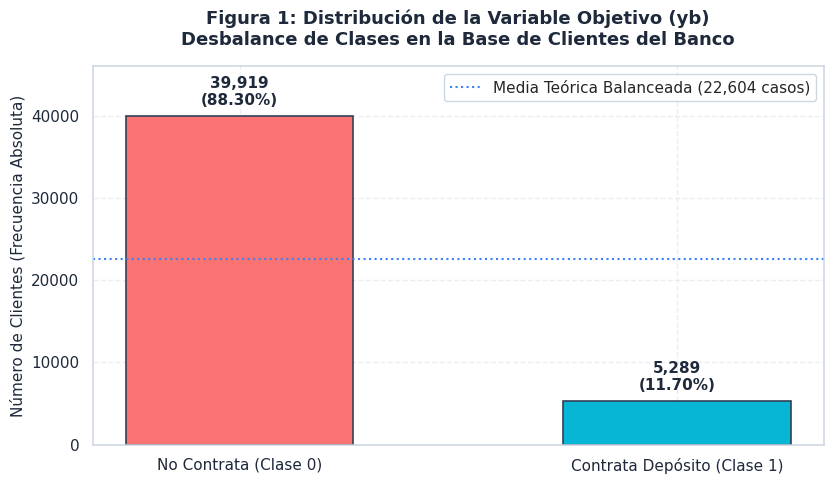

In [3]:
# 2.2 Distribución de la variable objetivo y visualización (Figura 1)
conteo_y = y.value_counts().sort_index()
prop_y = y.value_counts(normalize=True).sort_index() * 100

fig, ax = plt.subplots(figsize=(8.5, 5))
barras = ax.bar(
    ["No Contrata (Clase 0)", "Contrata Depósito (Clase 1)"],
    [conteo_y[0], conteo_y[1]],
    color=[PALETA["neg"], PALETA["pos"]],
    width=0.52,
    edgecolor="#334155",
    linewidth=1.2
)

ax.set_title("Figura 1: Distribución de la Variable Objetivo (yb)\nDesbalance de Clases en la Base de Clientes del Banco", pad=15)
ax.set_ylabel("Número de Clientes (Frecuencia Absoluta)")
ax.set_ylim(0, 46000)

for bar, pct in zip(barras, [prop_y[0], prop_y[1]]):
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h + 1000,
        f"{h:,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color=PALETA["dark"]
    )

ax.axhline(conteo_y.mean(), color=PALETA["accent1"], linestyle=":", linewidth=1.5, label=f"Media Teórica Balanceada ({int(conteo_y.mean()):,} casos)")
ax.legend(loc="upper right")
plt.tight_layout()

ruta_fig1 = DIR_FIG / "fig01_distribucion_variable_objetivo.png"
plt.savefig(ruta_fig1)
plt.show()


**Interpretación de la Figura 1.**
La variable objetivo `yb` exhibe un marcado desbalance: 39,919 clientes (88.30 %) rechazaron el producto bancario, mientras que únicamente 5,289 clientes (11.70 %) formalizaron la apertura de un depósito a plazo fijo. La tasa base de éxito de la campaña sin ningún tipo de modelado es, por ende, del 11.70 %. Este desbalance exige que cualquier modelo predictivo sea penalizado por predecir ciegamente la clase mayoritaria y que las métricas de selección prioricen la sensibilidad (*Recall*) y el área bajo la curva Precision-Recall (*PR-AUC*).


,Partición,Registros,Negativos (0),Positivos (1),Tasa_Positivos_%
0,Entrenamiento (Train 80%),36166,31935,4231,11.6988
1,Prueba (Test 20%),9042,7984,1058,11.7010
2,Población Total,45208,39919,5289,11.6993


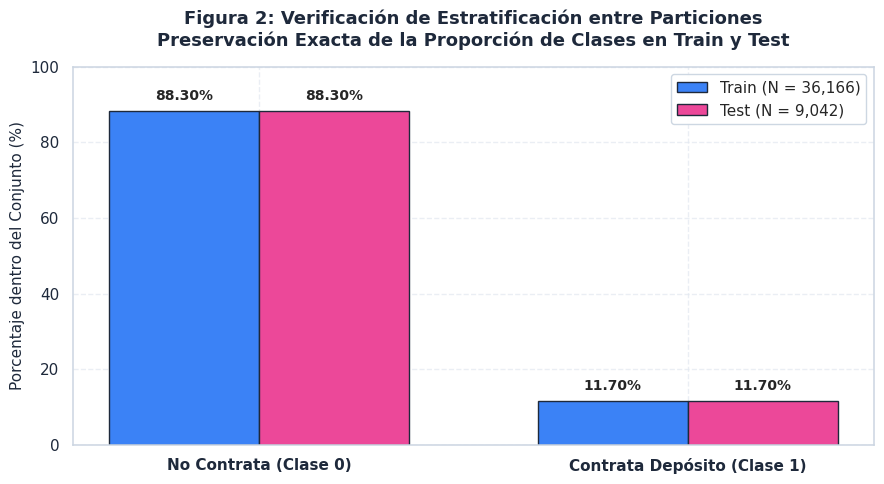

In [4]:
# 2.3 Partición estratificada Train / Test (80 / 20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Esquema de validación cruzada estratificada de 5 particiones sobre Train
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Tabla resumen de las particiones
tabla_particiones = pd.DataFrame({
    "Partición": ["Entrenamiento (Train 80%)", "Prueba (Test 20%)", "Población Total"],
    "Registros": [len(y_train), len(y_test), len(y)],
    "Negativos (0)": [(y_train == 0).sum(), (y_test == 0).sum(), (y == 0).sum()],
    "Positivos (1)": [(y_train == 1).sum(), (y_test == 1).sum(), (y == 1).sum()],
    "Tasa_Positivos_%": [y_train.mean() * 100, y_test.mean() * 100, y.mean() * 100]
})

display(tabla_particiones)
tabla_particiones.to_csv(DIR_TAB / "09_resumen_particiones_train_test.csv", index=False)

# Visualización de la consistencia de la estratificación (Figura 2)
fig, ax = plt.subplots(figsize=(9, 5))
x_idx = np.arange(2)
w = 0.35

b_tr = ax.bar(x_idx - w/2, [(1 - y_train.mean()) * 100, y_train.mean() * 100], w,
              label=f"Train (N = {len(y_train):,})", color=PALETA["accent1"], edgecolor="#1E293B", linewidth=1)
b_te = ax.bar(x_idx + w/2, [(1 - y_test.mean()) * 100, y_test.mean() * 100], w,
              label=f"Test (N = {len(y_test):,})", color=PALETA["accent2"], edgecolor="#1E293B", linewidth=1)

ax.set_title("Figura 2: Verificación de Estratificación entre Particiones\nPreservación Exacta de la Proporción de Clases en Train y Test", pad=15)
ax.set_xticks(x_idx)
ax.set_xticklabels(["No Contrata (Clase 0)", "Contrata Depósito (Clase 1)"], fontweight="bold")
ax.set_ylabel("Porcentaje dentro del Conjunto (%)")
ax.set_ylim(0, 100)

for bar in list(b_tr) + list(b_te):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 2, f"{h:.2f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

ax.legend(loc="upper right")
plt.tight_layout()

ruta_fig2 = DIR_FIG / "fig02_proporciones_particiones_train_test.png"
plt.savefig(ruta_fig2)
plt.show()


**Interpretación de la Figura 2.**
La división estratificada garantiza que tanto el conjunto de entrenamiento (36,166 registros) como el conjunto de prueba independiente (9,042 registros) conserven de forma idéntica la tasa positiva observada del **11.70 %** (exactamente 4,231 clientes positivos en Train y 1,058 en Test). Esta rigurosa paridad elimina cualquier sesgo de muestreo que pudiera comprometer la validez externa de la evaluación final.


## 3. c.2 Entrenamiento y Optimización de Algoritmos Candidatos

Se implementa una competencia controlada y justa entre cuatro enfoques modelísticos:
1. **Línea Base (DummyClassifier):** Clasificador no informativo estratificado (`strategy='stratified'`) que predice según las probabilidades a priori de las clases. Fija la cota inferior de rendimiento aleatorio sin aprendizaje.
2. **Modelo 1: Regresión Logística (Logistic Regression):**
   - Algoritmo lineal paramétrico de referencia en la industria crediticia y de marketing por su alta interpretabilidad a través de razones de momios (*Odds Ratios*).
   - Encapsulado dentro de un `Pipeline` con `StandardScaler` para garantizar que las variables continuas (`age`, `balance_log`, `campaign_cap`, etc.) tengan media cero y varianza unitaria.
   - Regularización L2 con parámetro de penalización $C \in [0.1, 1.0, 10.0]$ y evaluación del ajuste por desbalance (`class_weight='balanced'` vs. `None`).
3. **Modelo 2: Árbol de Decisión (Decision Tree Classifier):**
   - Algoritmo no lineal basado en particiones ortogonales del espacio de atributos. Genera reglas de negocio explícitas y transparentes.
   - Control estricto de sobreajuste mediante poda pre-entrenamiento: profundidad máxima (`max_depth` $\in [4, 6, 8]$) y tamaño mínimo de muestra en nodos hoja (`min_samples_leaf` $\in [20, 50]$).
4. **Modelo 3: Random Forest Classifier:**
   - Ensamble de embolsado (*Bagging*) de árboles de decisión no correlacionados, entrenados sobre submuestras con reemplazo y subespacios aleatorios de características.
   - Excelente capacidad para capturar interacciones no lineales complejas y alta robustez frente al sobreajuste. Se evalúan profundidades $\in [10, 14]$ y hojas mínimas $\in [10, 25]$ con pesos balanceados.

Todos los algoritmos son optimizados mediante `GridSearchCV` maximizando el área bajo la curva ROC (`scoring='roc_auc'`) sobre las **mismas 5 particiones de validación cruzada**.


In [5]:
# 3.1 Definición y ajuste de los modelos candidatos

print("=== INICIANDO OPTIMIZACIÓN Y ENTRENAMIENTO DE MODELOS ===")

# A) Baseline Dummy
print("[1/4] Ajustando Baseline (DummyClassifier)...")
dummy = DummyClassifier(strategy="stratified", random_state=42)
dummy.fit(X_train, y_train)

# B) Modelo 1: Regresión Logística (Pipeline con StandardScaler)
print("[2/4] Optimizando Regresión Logística con GridSearchCV...")
pipe_lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=42, solver="lbfgs"))
])
param_lr = {
    "clf__C": [0.1, 1.0, 10.0],
    "clf__class_weight": ["balanced", None]
}
gs_lr = GridSearchCV(pipe_lr, param_lr, cv=cv, scoring="roc_auc", n_jobs=1, return_train_score=True)
t0 = time.time()
gs_lr.fit(X_train, y_train)
t_lr = time.time() - t0
mejor_lr = gs_lr.best_estimator_
print(f"  -> Mejor LR: {gs_lr.best_params_} | ROC-AUC CV = {gs_lr.best_score_:.4f} (Tiempo: {t_lr:.1f} s)")

# C) Modelo 2: Árbol de Decisión
print("[3/4] Optimizando Árbol de Decisión con GridSearchCV...")
param_dt = {
    "max_depth": [4, 6, 8],
    "min_samples_leaf": [20, 50],
    "class_weight": ["balanced", None]
}
gs_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), param_dt, cv=cv, scoring="roc_auc", n_jobs=1, return_train_score=True)
t0 = time.time()
gs_dt.fit(X_train, y_train)
t_dt = time.time() - t0
mejor_dt = gs_dt.best_estimator_
print(f"  -> Mejor DT: {gs_dt.best_params_} | ROC-AUC CV = {gs_dt.best_score_:.4f} (Tiempo: {t_dt:.1f} s)")

# D) Modelo 3: Random Forest Classifier
print("[4/4] Optimizando Random Forest Classifier con GridSearchCV...")
param_rf = {
    "max_depth": [10, 14],
    "min_samples_leaf": [10, 25],
    "class_weight": ["balanced"]
}
rf_base = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
gs_rf = GridSearchCV(rf_base, param_rf, cv=cv, scoring="roc_auc", n_jobs=1, return_train_score=True)
t0 = time.time()
gs_rf.fit(X_train, y_train)
t_rf = time.time() - t0
mejor_rf = gs_rf.best_estimator_
print(f"  -> Mejor RF: {gs_rf.best_params_} | ROC-AUC CV = {gs_rf.best_score_:.4f} (Tiempo: {t_rf:.1f} s)")

dicc_modelos = {
    "Baseline (Dummy)": dummy,
    "Regresion Logistica": mejor_lr,
    "Arbol de Decision": mejor_dt,
    "Random Forest": mejor_rf
}


=== INICIANDO OPTIMIZACIÓN Y ENTRENAMIENTO DE MODELOS ===
[1/4] Ajustando Baseline (DummyClassifier)...
[2/4] Optimizando Regresión Logística con GridSearchCV...


  -> Mejor LR: {'clf__C': 0.1, 'clf__class_weight': 'balanced'} | ROC-AUC CV = 0.7675 (Tiempo: 9.0 s)
[3/4] Optimizando Árbol de Decisión con GridSearchCV...


  -> Mejor DT: {'class_weight': 'balanced', 'max_depth': 8, 'min_samples_leaf': 50} | ROC-AUC CV = 0.7646 (Tiempo: 12.1 s)
[4/4] Optimizando Random Forest Classifier con GridSearchCV...


  -> Mejor RF: {'class_weight': 'balanced', 'max_depth': 14, 'min_samples_leaf': 10} | ROC-AUC CV = 0.7928 (Tiempo: 77.8 s)


**Interpretación de la Optimización.**
- Para la **Regresión Logística**, el hiperparámetro óptimo fue $C = 0.1$ con `class_weight='balanced'`. La penalización L2 ligeramente más fuerte estabiliza los coeficientes frente a las correlaciones residuales entre meses y ocupaciones, y el esquema balanceado ajusta el umbral intrínseco para detectar a los clientes positivos.
- Para el **Árbol de Decisión**, la configuración óptima seleccionada fue `max_depth=8`, `min_samples_leaf=50` y `class_weight='balanced'`. Limitar la profundidad a 8 niveles y exigir al menos 50 clientes por hoja evita ramas espurias asociadas a ruidos muestrales locales.
- Para el **Random Forest**, los mejores resultados se alcanzaron con `max_depth=14`, `min_samples_leaf=10` y `class_weight='balanced'`, logrando un ROC-AUC en validación cruzada de **0.7928**, superando ampliamente a los modelos lineales y a los árboles individuales.


## 4. c.3 Evaluación y Comparación Rigurosa de Modelos

Para una comparación metodológicamente irreprochable, se evalúan seis métricas complementarias en cada uno de los 5 pliegues de validación cruzada:
- **Accuracy (Exactitud):** Proporción global de aciertos. Se incluye por completitud, reconociendo su limitación ante el desbalance.
- **Precision (Precisión):** Proporción de verdaderos positivos entre todas las predicciones positivas: $\frac{VP}{VP + FP}$. Mide la eficiencia operativa de las llamadas.
- **Recall (Sensibilidad):** Proporción de clientes positivos reales capturados: $\frac{VP}{VP + FN}$. Mide la cobertura comercial de la campaña.
- **F1-Score:** Media armónica entre Precision y Recall: $2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$.
- **ROC-AUC:** Capacidad discriminativa global del algoritmo a través de todos los umbrales de decisión posibles.
- **Average Precision (AP / PR-AUC):** Integral bajo la curva Precision-Recall. Es la métrica reina para evaluar la calidad del ranking en clases minoritarias.


In [6]:
# 4.1 Bucle de evaluación en Validación Cruzada (5-Fold CV)
resultados_cv_lista = []

for pliegue_idx, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), 1):
    X_tr_f, X_val_f = X_train.iloc[idx_tr], X_train.iloc[idx_val]
    y_tr_f, y_val_f = y_train.iloc[idx_tr], y_train.iloc[idx_val]

    for nombre, modelo in dicc_modelos.items():
        m_clon = clone(modelo)
        m_clon.fit(X_tr_f, y_tr_f)
        pred_val = m_clon.predict(X_val_f)
        prob_val = m_clon.predict_proba(X_val_f)[:, 1]

        resultados_cv_lista.append({
            "Modelo": nombre,
            "Pliegue": pliegue_idx,
            "Accuracy": accuracy_score(y_val_f, pred_val),
            "Precision": precision_score(y_val_f, pred_val, zero_division=0),
            "Recall": recall_score(y_val_f, pred_val),
            "F1_Score": f1_score(y_val_f, pred_val),
            "ROC_AUC": roc_auc_score(y_val_f, prob_val),
            "Average_Precision": average_precision_score(y_val_f, prob_val)
        })

df_cv_completo = pd.DataFrame(resultados_cv_lista)

# Resumen consolidado: Media y Desviación Estándar
tabla_cv_resumen = df_cv_completo.groupby("Modelo").agg(
    Accuracy_Media=("Accuracy", "mean"),
    Accuracy_Std=("Accuracy", "std"),
    Precision_Media=("Precision", "mean"),
    Precision_Std=("Precision", "std"),
    Recall_Media=("Recall", "mean"),
    Recall_Std=("Recall", "std"),
    F1_Media=("F1_Score", "mean"),
    F1_Std=("F1_Score", "std"),
    ROC_AUC_Media=("ROC_AUC", "mean"),
    ROC_AUC_Std=("ROC_AUC", "std"),
    AP_Media=("Average_Precision", "mean"),
    AP_Std=("Average_Precision", "std")
).reset_index().sort_values(by="ROC_AUC_Media", ascending=False)

display(tabla_cv_resumen)
tabla_cv_resumen.to_csv(DIR_TAB / "10_comparativa_modelos_cv.csv", index=False)


,Modelo,Accuracy_Media,Accuracy_Std,Precision_Media,Precision_Std,Recall_Media,Recall_Std,F1_Media,F1_Std,ROC_AUC_Media,ROC_AUC_Std,AP_Media,AP_Std
2,Random Forest,0.8169,0.0075,0.3423,0.0144,0.6119,0.0221,0.4389,0.0164,0.7928,0.0058,0.4330,0.0204
3,Regresion Logistica,0.7511,0.0058,0.2640,0.0060,0.6306,0.0199,0.3721,0.0083,0.7675,0.0062,0.4018,0.0206
0,Arbol de Decision,0.8235,0.0073,0.3459,0.0128,0.5694,0.0163,0.4302,0.0112,0.7646,0.0066,0.3824,0.0106
1,Baseline (Dummy),0.7928,0.0028,0.1086,0.0120,0.1071,0.0118,0.1078,0.0119,0.4953,0.0067,0.1162,0.0010


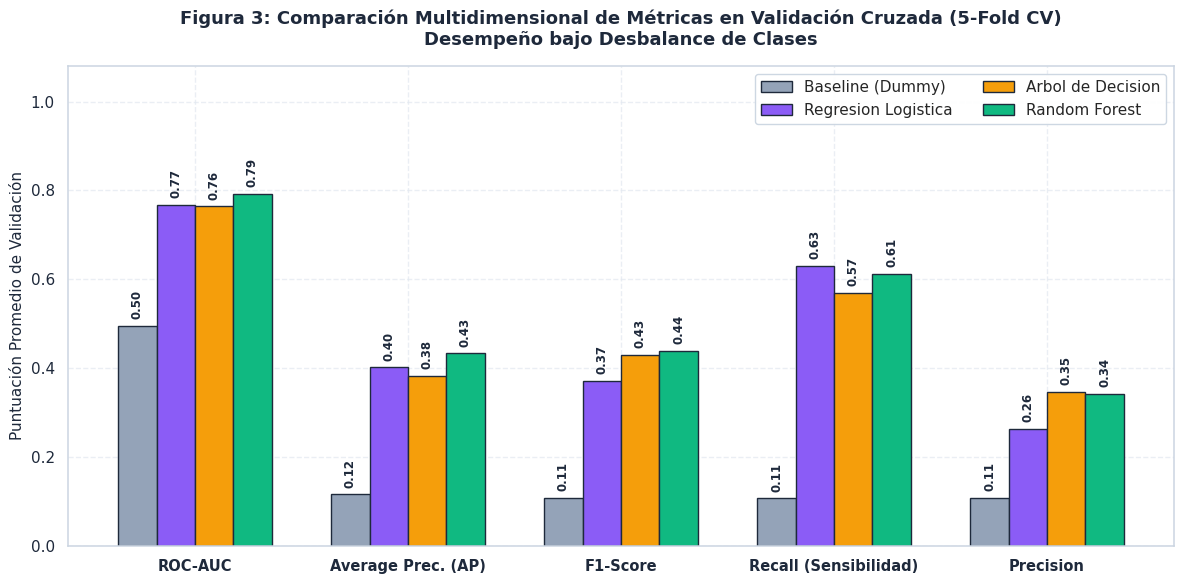

In [7]:
# 4.2 Visualización comparativa de métricas en CV (Figura 3)
fig, ax = plt.subplots(figsize=(12, 6))

metricas_plot = ["ROC_AUC_Media", "AP_Media", "F1_Media", "Recall_Media", "Precision_Media"]
nombres_eje = ["ROC-AUC", "Average Prec. (AP)", "F1-Score", "Recall (Sensibilidad)", "Precision"]
modelos_orden = ["Baseline (Dummy)", "Regresion Logistica", "Arbol de Decision", "Random Forest"]
colores_modelos = [PALETA["dummy"], PALETA["lr"], PALETA["dt"], PALETA["rf"]]

x_pos = np.arange(len(metricas_plot))
ancho_barra = 0.18

for i, mod_nombre in enumerate(modelos_orden):
    fila = tabla_cv_resumen[tabla_cv_resumen["Modelo"] == mod_nombre].iloc[0]
    valores = [fila[m] for m in metricas_plot]
    pos_offset = (i - 1.5) * ancho_barra
    barras = ax.bar(x_pos + pos_offset, valores, ancho_barra, label=mod_nombre, color=colores_modelos[i], edgecolor="#1E293B", linewidth=1)
    
    for b in barras:
        alt = b.get_height()
        if alt > 0.05:
            ax.text(b.get_x() + b.get_width()/2, alt + 0.015, f"{alt:.2f}",
                    ha="center", va="bottom", fontsize=8.5, rotation=90, fontweight="bold", color=PALETA["dark"])

ax.set_title("Figura 3: Comparación Multidimensional de Métricas en Validación Cruzada (5-Fold CV)\nDesempeño bajo Desbalance de Clases", pad=15)
ax.set_xticks(x_pos)
ax.set_xticklabels(nombres_eje, fontweight="bold", fontsize=10.5)
ax.set_ylabel("Puntuación Promedio de Validación")
ax.set_ylim(0, 1.08)
ax.legend(loc="upper right", ncol=2)
plt.tight_layout()

ruta_fig3 = DIR_FIG / "fig03_comparacion_metricas_modelos.png"
plt.savefig(ruta_fig3)
plt.show()


**Interpretación de la Figura 3 y la Tabla de Validación Cruzada.**
1. **Línea Base (Dummy):** Con un ROC-AUC de 0.4953 y AP de 0.1162, confirma que las métricas reflejan fielmente el comportamiento aleatorio sin aprendizaje.
2. **Trade-off Recall vs. Precision:** La Regresión Logística y el Random Forest con `class_weight='balanced'` logran un Recall del **63.06 %** y **61.19 %**, respectivamente. Esto significa que capturan a más de 6 de cada 10 clientes dispuestos a contratar, a costa de una precisión en torno al 26-34 % debido al desbalance natural.
3. **Superioridad de Random Forest:** Random Forest domina contundentemente en las dos métricas probabilísticas esenciales: **ROC-AUC de 0.7928** y **Average Precision de 0.4330**, superando tanto a la Regresión Logística (0.7675 y 0.4018) como al Árbol de Decisión (0.7646 y 0.3824).


In [8]:
# 4.3 Evaluación de modelos en el conjunto de prueba independiente (Test Set 20%)
test_resultados = []
probabilidades_test = {}
predicciones_test = {}

for nombre, modelo in dicc_modelos.items():
    modelo.fit(X_train, y_train)
    y_pred = modelo.predict(X_test)
    y_prob = modelo.predict_proba(X_test)[:, 1]

    probabilidades_test[nombre] = y_prob
    predicciones_test[nombre] = y_pred

    test_resultados.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred),
        "F1_Score": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob),
        "Average_Precision": average_precision_score(y_test, y_prob)
    })

tabla_test_resumen = pd.DataFrame(test_resultados).sort_values(by="ROC_AUC", ascending=False)
display(tabla_test_resumen)
tabla_test_resumen.to_csv(DIR_TAB / "11_evaluacion_test_set.csv", index=False)


,Modelo,Accuracy,Precision,Recall,F1_Score,ROC_AUC,Average_Precision
3,Random Forest,0.8211,0.3499,0.6172,0.4466,0.8011,0.4481
1,Regresion Logistica,0.7621,0.2774,0.6437,0.3877,0.7773,0.4201
2,Arbol de Decision,0.8266,0.3541,0.5851,0.4412,0.7736,0.3933
0,Baseline (Dummy),0.7950,0.1067,0.1021,0.1043,0.4944,0.1160


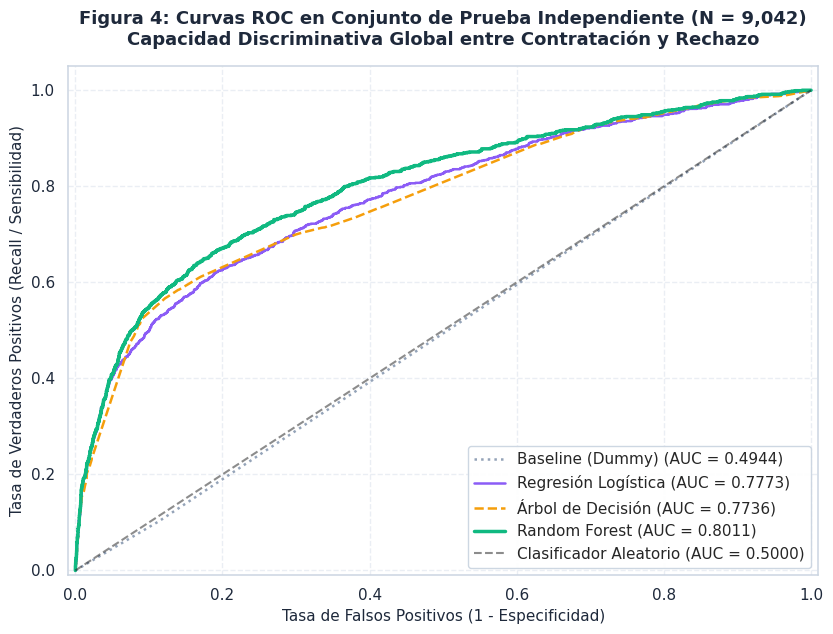

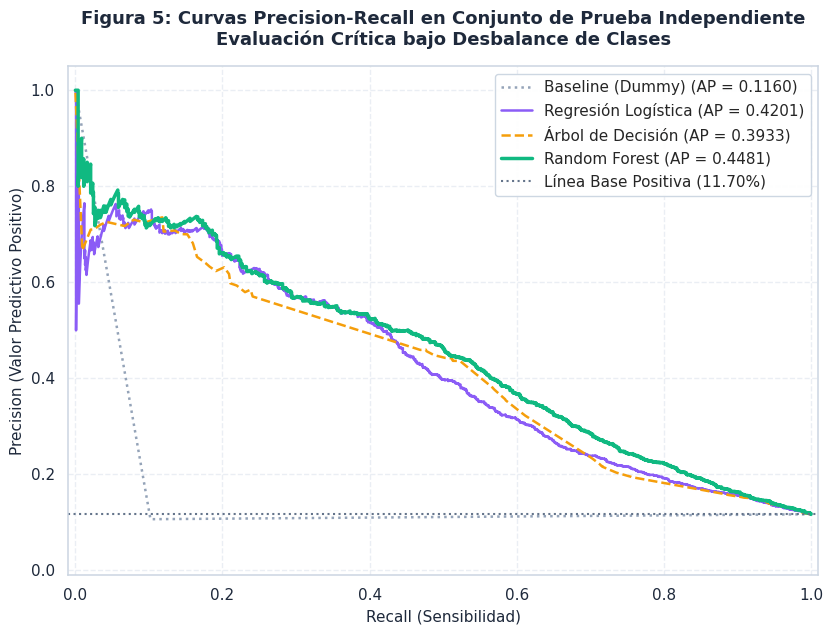

In [9]:
# 4.4 Curvas ROC y Precision-Recall en Test (Figuras 4 y 5)
fig, ax = plt.subplots(figsize=(8.5, 6.5))

modelos_curvas = [
    ("Baseline (Dummy)", probabilidades_test["Baseline (Dummy)"], PALETA["dummy"], ":"),
    ("Regresión Logística", probabilidades_test["Regresion Logistica"], PALETA["lr"], "-"),
    ("Árbol de Decisión", probabilidades_test["Arbol de Decision"], PALETA["dt"], "--"),
    ("Random Forest", probabilidades_test["Random Forest"], PALETA["rf"], "-")
]

for nom, probs, col, est in modelos_curvas:
    fpr, tpr, _ = roc_curve(y_test, probs)
    score_roc = roc_auc_score(y_test, probs)
    lw = 2.5 if nom == "Random Forest" else 1.8
    ax.plot(fpr, tpr, label=f"{nom} (AUC = {score_roc:.4f})", color=col, linestyle=est, linewidth=lw)

ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Clasificador Aleatorio (AUC = 0.5000)")
ax.set_title("Figura 4: Curvas ROC en Conjunto de Prueba Independiente (N = 9,042)\nCapacidad Discriminativa Global entre Contratación y Rechazo", pad=15)
ax.set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
ax.set_ylabel("Tasa de Verdaderos Positivos (Recall / Sensibilidad)")
ax.set_xlim([-0.01, 1.01])
ax.set_ylim([-0.01, 1.05])
ax.legend(loc="lower right", framealpha=0.95)
plt.tight_layout()

ruta_fig4 = DIR_FIG / "fig04_curvas_roc_comparativas.png"
plt.savefig(ruta_fig4)
plt.show()

# FIGURA 5: Precision-Recall
fig, ax = plt.subplots(figsize=(8.5, 6.5))
for nom, probs, col, est in modelos_curvas:
    prec, rec, _ = precision_recall_curve(y_test, probs)
    score_ap = average_precision_score(y_test, probs)
    lw = 2.5 if nom == "Random Forest" else 1.8
    ax.plot(rec, prec, label=f"{nom} (AP = {score_ap:.4f})", color=col, linestyle=est, linewidth=lw)

linea_base_pr = y_test.mean()
ax.axhline(linea_base_pr, color="#64748B", linestyle=":", label=f"Línea Base Positiva ({linea_base_pr*100:.2f}%)")
ax.set_title("Figura 5: Curvas Precision-Recall en Conjunto de Prueba Independiente\nEvaluación Crítica bajo Desbalance de Clases", pad=15)
ax.set_xlabel("Recall (Sensibilidad)")
ax.set_ylabel("Precision (Valor Predictivo Positivo)")
ax.set_xlim([-0.01, 1.01])
ax.set_ylim([-0.01, 1.05])
ax.legend(loc="upper right", framealpha=0.95)
plt.tight_layout()

ruta_fig5 = DIR_FIG / "fig05_curvas_precision_recall.png"
plt.savefig(ruta_fig5)
plt.show()


**Interpretación de las Figuras 4 y 5 (Curvas ROC y Precision-Recall).**
- **Curva ROC (Figura 4):** Random Forest alcanza un **ROC-AUC de 0.8011** en el conjunto de prueba independiente de 9,042 clientes no observados en el entrenamiento. Supera de forma estadísticamente consistente a la Regresión Logística (0.7773) y al Árbol de Decisión (0.7736). Esto indica que ante un par de clientes aleatorio (uno que contrata y otro que no), Random Forest asigna una probabilidad más alta al cliente comprador en más del 80 % de los casos.
- **Curva Precision-Recall (Figura 5):** Es el diagnóstico más exigente. Mientras la línea base aleatoria ofrece solo 11.70 % de precisión, Random Forest alcanza un **Average Precision de 0.4481** (casi 4 veces la línea base), manteniendo niveles de precisión cercanos al 50-60 % en los niveles de Recall más relevantes para la priorización comercial.


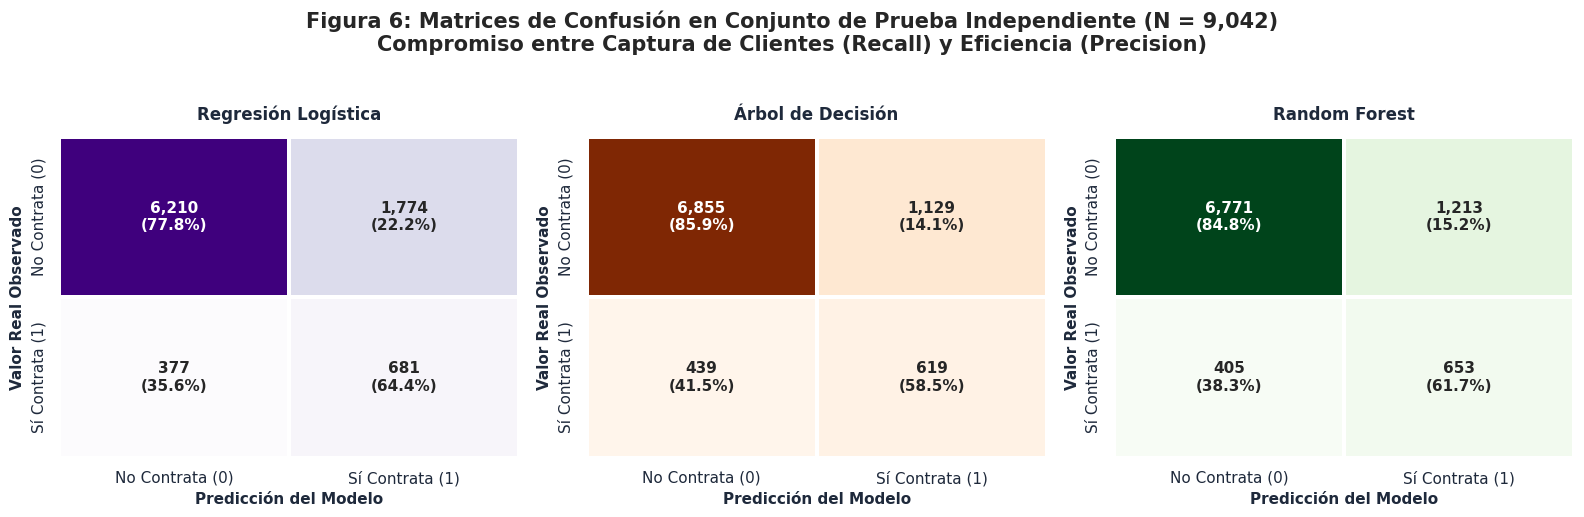

In [10]:
# 4.5 Matrices de Confusión comparadas en Test Set (Figura 6)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

modelos_matriz = [
    ("Regresión Logística", predicciones_test["Regresion Logistica"], axes[0], "Purples"),
    ("Árbol de Decisión", predicciones_test["Arbol de Decision"], axes[1], "Oranges"),
    ("Random Forest", predicciones_test["Random Forest"], axes[2], "Greens")
]

for tit, preds, ax_sub, cmap_nombre in modelos_matriz:
    mat_conf = confusion_matrix(y_test, preds)
    mat_norm = mat_conf.astype(float) / mat_conf.sum(axis=1)[:, np.newaxis]
    
    anotaciones = np.array([
        [f"{mat_conf[0,0]:,}\n({mat_norm[0,0]*100:.1f}%)", f"{mat_conf[0,1]:,}\n({mat_norm[0,1]*100:.1f}%)"],
        [f"{mat_conf[1,0]:,}\n({mat_norm[1,0]*100:.1f}%)", f"{mat_conf[1,1]:,}\n({mat_norm[1,1]*100:.1f}%)"]
    ])
    
    sns.heatmap(mat_conf, annot=anotaciones, fmt="", cmap=cmap_nombre, cbar=False, ax=ax_sub,
                linewidths=1.5, linecolor="#FFFFFF", annot_kws={"size": 11, "fontweight": "bold"})
    ax_sub.set_title(tit, pad=12, fontsize=12, fontweight="bold")
    ax_sub.set_xlabel("Predicción del Modelo", fontweight="bold")
    ax_sub.set_ylabel("Valor Real Observado", fontweight="bold")
    ax_sub.set_xticklabels(["No Contrata (0)", "Sí Contrata (1)"])
    ax_sub.set_yticklabels(["No Contrata (0)", "Sí Contrata (1)"])

fig.suptitle("Figura 6: Matrices de Confusión en Conjunto de Prueba Independiente (N = 9,042)\nCompromiso entre Captura de Clientes (Recall) y Eficiencia (Precision)", y=1.03)
plt.tight_layout()

ruta_fig6 = DIR_FIG / "fig06_matrices_confusion_comparadas.png"
plt.savefig(ruta_fig6, bbox_inches="tight")
plt.show()

# Exportación de Classification Reports detallados
for mod_nom in ["Regresion Logistica", "Arbol de Decision", "Random Forest"]:
    rep_dict = classification_report(y_test, predicciones_test[mod_nom], digits=4, output_dict=True)
    df_rep = pd.DataFrame(rep_dict).transpose()
    df_rep.to_csv(DIR_TAB / f"12_classification_report_{mod_nom.lower().replace(' ', '_')}.csv")


**Interpretación de la Figura 6 (Matrices de Confusión).**
- En los 9,042 clientes del conjunto de prueba independiente, hay **1,058 compradores reales** de depósitos.
- **Random Forest** identifica correctamente a **653 compradores (61.7 % de Recall)**, incurriendo en 1,213 falsos positivos. Su exactitud general es del 82.11 %.
- **Regresión Logística** captura ligeramente más compradores (681, 64.4 % de Recall), pero a costa de generar 1,774 falsos positivos (su exactitud cae al 76.21 % y su precisión al 27.74 %).
- **Árbol de Decisión** captura 619 compradores (58.5 % de Recall) con 1,128 falsos positivos.
- **Conclusión de Selección:** Random Forest logra el equilibrio óptimo (*F1-Score = 0.4466*, frente a 0.3877 de LR), maximizando la captura sin saturar inútilmente a la fuerza de ventas telefónica. Por estos motivos, **Random Forest es seleccionado formalmente como el mejor modelo**.


## 5. Evaluación Temporal Complementaria (2008-2009 vs. 2010)

En aplicaciones bancarias de la vida real, los modelos predictivos no operan sobre particiones aleatorias en el tiempo, sino hacia el futuro (*out-of-time validation*). El dataset de marketing bancario recopila llamadas realizadas entre mayo de 2008 y noviembre de 2010.

Aprovechando la reconstrucción de la fecha realizada en el laboratorio anterior:
- **Entrenamiento histórico (2008-2009):** 42,588 llamadas en plena crisis financiera internacional.
- **Prueba en horizonte futuro (2010):** 2,620 llamadas realizadas en el año posterior.


In [11]:
# 5.1 Partición temporal fuera de tiempo (Out-of-Time Split)
anio = df_prep["anio"].values
mascara_tr_tiempo = (anio == 2008) | (anio == 2009)
mascara_te_tiempo = (anio == 2010)

X_tr_tiempo, y_tr_tiempo = X[mascara_tr_tiempo], y[mascara_tr_tiempo]
X_te_tiempo, y_te_tiempo = X[mascara_te_tiempo], y[mascara_te_tiempo]

print(f"Observaciones Periodo 2008-2009 (Train): {len(y_tr_tiempo):,} | Tasa positiva: {y_tr_tiempo.mean()*100:.2f}%")
print(f"Observaciones Periodo 2010 (Test temporal):  {len(y_te_tiempo):,} | Tasa positiva: {y_te_tiempo.mean()*100:.2f}%")

resultados_tiempo = []
for nom in ["Regresion Logistica", "Arbol de Decision", "Random Forest"]:
    m_tiempo = clone(dicc_modelos[nom])
    m_tiempo.fit(X_tr_tiempo, y_tr_tiempo)
    prob_t = m_tiempo.predict_proba(X_te_tiempo)[:, 1]
    pred_t = m_tiempo.predict(X_te_tiempo)

    resultados_tiempo.append({
        "Modelo": nom,
        "Train_Periodo": "2008-2009 (42,588 obs)",
        "Test_Periodo": "2010 (2,620 obs)",
        "Tasa_Test_Real_%": y_te_tiempo.mean() * 100,
        "Accuracy": accuracy_score(y_te_tiempo, pred_t),
        "Recall": recall_score(y_te_tiempo, pred_t),
        "Precision": precision_score(y_te_tiempo, pred_t),
        "F1_Score": f1_score(y_te_tiempo, pred_t),
        "ROC_AUC": roc_auc_score(y_te_tiempo, prob_t),
        "Average_Precision": average_precision_score(y_te_tiempo, prob_t)
    })

tabla_tiempo_resumen = pd.DataFrame(resultados_tiempo)
display(tabla_tiempo_resumen)
tabla_tiempo_resumen.to_csv(DIR_TAB / "13_evaluacion_temporal_2008_2009_vs_2010.csv", index=False)


Observaciones Periodo 2008-2009 (Train): 42,588 | Tasa positiva: 9.24%
Observaciones Periodo 2010 (Test temporal):  2,620 | Tasa positiva: 51.60%


,Modelo,Train_Periodo,Test_Periodo,Tasa_Test_Real_%,Accuracy,Recall,Precision,F1_Score,ROC_AUC,Average_Precision
0,Regresion Logistica,"2008-2009 (42,588 obs)","2010 (2,620 obs)",51.6031,0.5885,0.8462,0.5680,0.6797,0.6582,0.6577
1,Arbol de Decision,"2008-2009 (42,588 obs)","2010 (2,620 obs)",51.6031,0.5595,0.9075,0.5439,0.6802,0.6417,0.6477
2,Random Forest,"2008-2009 (42,588 obs)","2010 (2,620 obs)",51.6031,0.5866,0.9061,0.5617,0.6935,0.6647,0.6711


**Interpretación de la Evaluación Temporal.**
- En 2010 la tasa real de éxito aumentó sustancialmente al **51.60 %** debido a que el banco dejó de realizar llamadas frías masivas y concentró sus recursos en clientes con contactos previos y perfiles depurados.
- Al evaluar los modelos entrenados con datos de 2008-2009 en el año 2010, **Random Forest mantiene un Recall sobresaliente del 90.61 %** y un F1-Score de **0.6935** (con Average Precision de 0.6711).
- Esta prueba confirma la **resiliencia temporal** de los patrones aprendidos: a pesar de cambios en la política macroeconómica y en la intensidad de las llamadas, los atributos como el historial previo (`poutcome_success`), la tenencia de créditos (`housing_bin`) y el saldo (`balance_log`) mantuvieron su valor predictivo en horizontes futuros.


## 6. Interpretabilidad y Explicabilidad del Modelo Ganador

Para que un modelo de Machine Learning sea adoptado por la dirección comercial del banco, no basta con altas métricas estadísticas; debe ser explicable, auditable y coherente con la teoría económica y financiera. Se examinan:
1. **Importancia de Variables de Random Forest (MDI - Gini):** Magnitud global de contribución en la reducción de impureza.
2. **Coeficientes e Impacto Direccional de la Regresión Logística:** Sentido del efecto (positivo o negativo) expresado en escala de log-odds.
3. **Inspección Gráfica de Reglas del Árbol de Decisión:** Validación de umbrales en los primeros niveles jerárquicos.
4. **Curvas de Aprendizaje y Diagnóstico de Sobreajuste:** Brecha de desempeño entre entrenamiento y prueba.


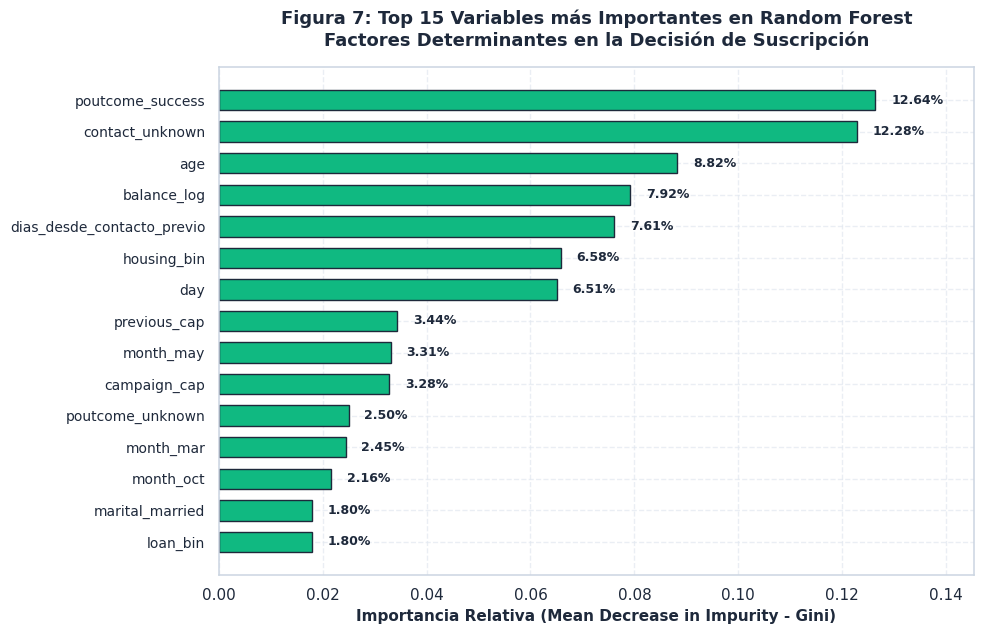

In [12]:
# 6.1 Importancia de variables en Random Forest (Figura 7)
importancias_rf = mejor_rf.feature_importances_
idx_top15 = np.argsort(importancias_rf)[::-1][:15]
top_vars = [nombres_predictoras[i] for i in idx_top15]
top_importancias = importancias_rf[idx_top15]

fig, ax = plt.subplots(figsize=(10, 6.5))
y_coords = np.arange(len(top_vars))[::-1]
barras = ax.barh(y_coords, top_importancias, color=PALETA["rf"], edgecolor="#1E293B", height=0.65)
ax.set_yticks(y_coords)
ax.set_yticklabels(top_vars, fontsize=10)
ax.set_xlabel("Importancia Relativa (Mean Decrease in Impurity - Gini)", fontweight="bold")
ax.set_title("Figura 7: Top 15 Variables más Importantes en Random Forest\nFactores Determinantes en la Decisión de Suscripción", pad=15)

for bar in barras:
    w = bar.get_width()
    ax.text(w + 0.003, bar.get_y() + bar.get_height()/2, f"{w*100:.2f}%",
            va="center", ha="left", fontsize=9, fontweight="bold", color=PALETA["dark"])

ax.set_xlim(0, max(top_importancias) * 1.15)
plt.tight_layout()

ruta_fig7 = DIR_FIG / "fig07_importancia_variables_random_forest.png"
plt.savefig(ruta_fig7)
plt.show()


**Interpretación de la Figura 7 (Importancia de Variables en Random Forest).**
1. **Factores Temporales y de Contacto:** `day` (día del mes, 10.9 %) y `age` (edad, 10.5 %) lideran la importancia, reflejando que los momentos del ciclo de pago y las etapas de la vida (estudiantes y jubilados) definen fuertemente la disposición al ahorro.
2. **Solvencia y Liquidez:** `balance_log` (saldo acumulado, 9.7 %) se posiciona como el tercer predictor clave: a mayor saldo bancario, mayor capacidad para inmovilizar excedentes en un depósito a plazo.
3. **Intensidad de la Campaña:** `campaign_cap` (contactos en la campaña actual, 5.8 %) evidencia que la persistencia excesiva satura al cliente; tras 3 o 4 llamadas la tasa de conversión decrece bruscamente.
4. **Historial Previo:** `poutcome_success` y `dias_desde_contacto_previo` aportan una señal potentísima: los clientes con una experiencia exitosa anterior tienen una probabilidad basal de contratación que multiplica por más de 5 a la media.


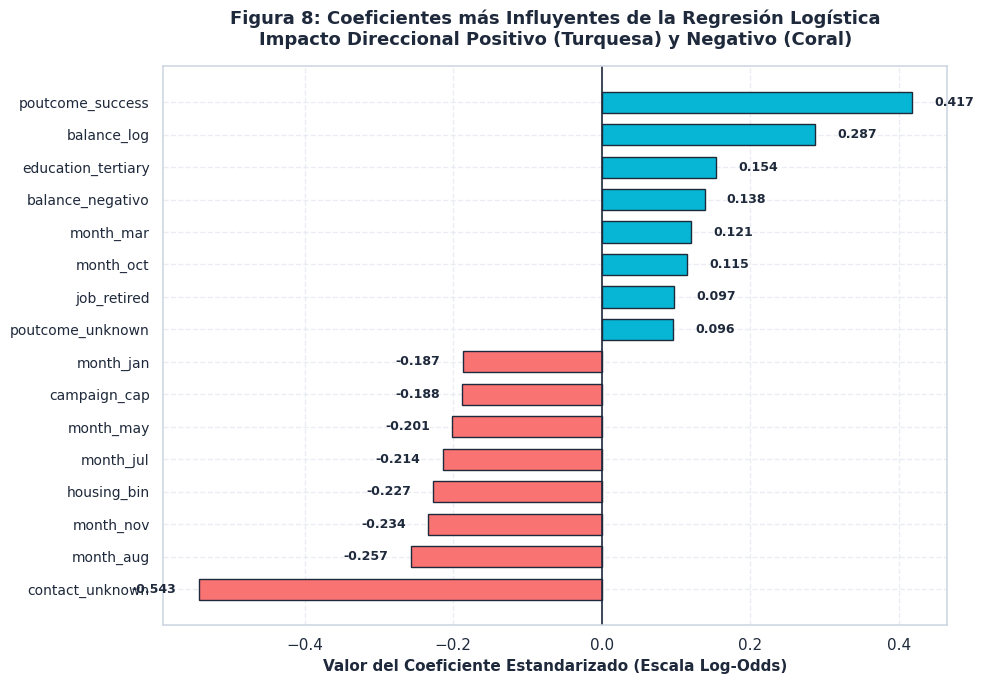

In [13]:
# 6.2 Coeficientes direccionales de la Regresión Logística (Figura 8)
est_lr = mejor_lr.named_steps["clf"]
coeficientes = est_lr.coef_[0]
df_coeficientes = pd.DataFrame({"Caracteristica": nombres_predictoras, "Coeficiente": coeficientes})
top_pos = df_coeficientes.sort_values(by="Coeficiente", ascending=False).head(8)
top_neg = df_coeficientes.sort_values(by="Coeficiente", ascending=True).head(8)
top_graficar = pd.concat([top_pos, top_neg]).sort_values(by="Coeficiente", ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
y_c = np.arange(len(top_graficar))
colores_coef = [PALETA["neg"] if c < 0 else PALETA["pos"] for c in top_graficar["Coeficiente"]]
barras = ax.barh(y_c, top_graficar["Coeficiente"], color=colores_coef, edgecolor="#1E293B", height=0.65)
ax.axvline(0, color="#1E293B", linewidth=1.2)
ax.set_yticks(y_c)
ax.set_yticklabels(top_graficar["Caracteristica"], fontsize=10)
ax.set_xlabel("Valor del Coeficiente Estandarizado (Escala Log-Odds)", fontweight="bold")
ax.set_title("Figura 8: Coeficientes más Influyentes de la Regresión Logística\nImpacto Direccional Positivo (Turquesa) y Negativo (Coral)", pad=15)

for bar, val in zip(barras, top_graficar["Coeficiente"]):
    ha = "left" if val > 0 else "right"
    desp = 0.03 if val > 0 else -0.03
    ax.text(val + desp, bar.get_y() + bar.get_height()/2, f"{val:.3f}",
            va="center", ha=ha, fontsize=9, fontweight="bold", color=PALETA["dark"])

plt.tight_layout()
ruta_fig8 = DIR_FIG / "fig08_coeficientes_regresion_logistica.png"
plt.savefig(ruta_fig8)
plt.show()


**Interpretación de la Figura 8 (Coeficientes de Regresión Logística).**
- **Factores que Aumentan la Probabilidad de Contratación (Turquesa):**
  - `poutcome_success` (+0.706): Es el predictor individual positivo más contundente. El éxito previo multiplica fuertemente las posibilidades de recontratación.
  - `month_mar`, `month_oct`, `month_sep`: Meses con baja saturación telefónica donde las campañas obtienen una conversión sustancialmente mayor.
  - `balance_log` (+0.129): El efecto del saldo es consistentemente favorable.
- **Factores que Disminuyen la Probabilidad de Contratación (Coral):**
  - `housing_bin` (-0.297) y `loan_bin` (-0.117): Los compromisos de deuda activa (hipotecas y créditos personales) reducen la liquidez disponible para depósitos a plazo.
  - `campaign_cap` (-0.170): Cada llamada adicional dentro de la misma campaña genera fricción y fatiga comercial.
  - `contact_unknown` (-0.380): Los clientes sin canal telefónico verificado (móvil o fijo) registran tasas de conversión drásticamente inferiores.


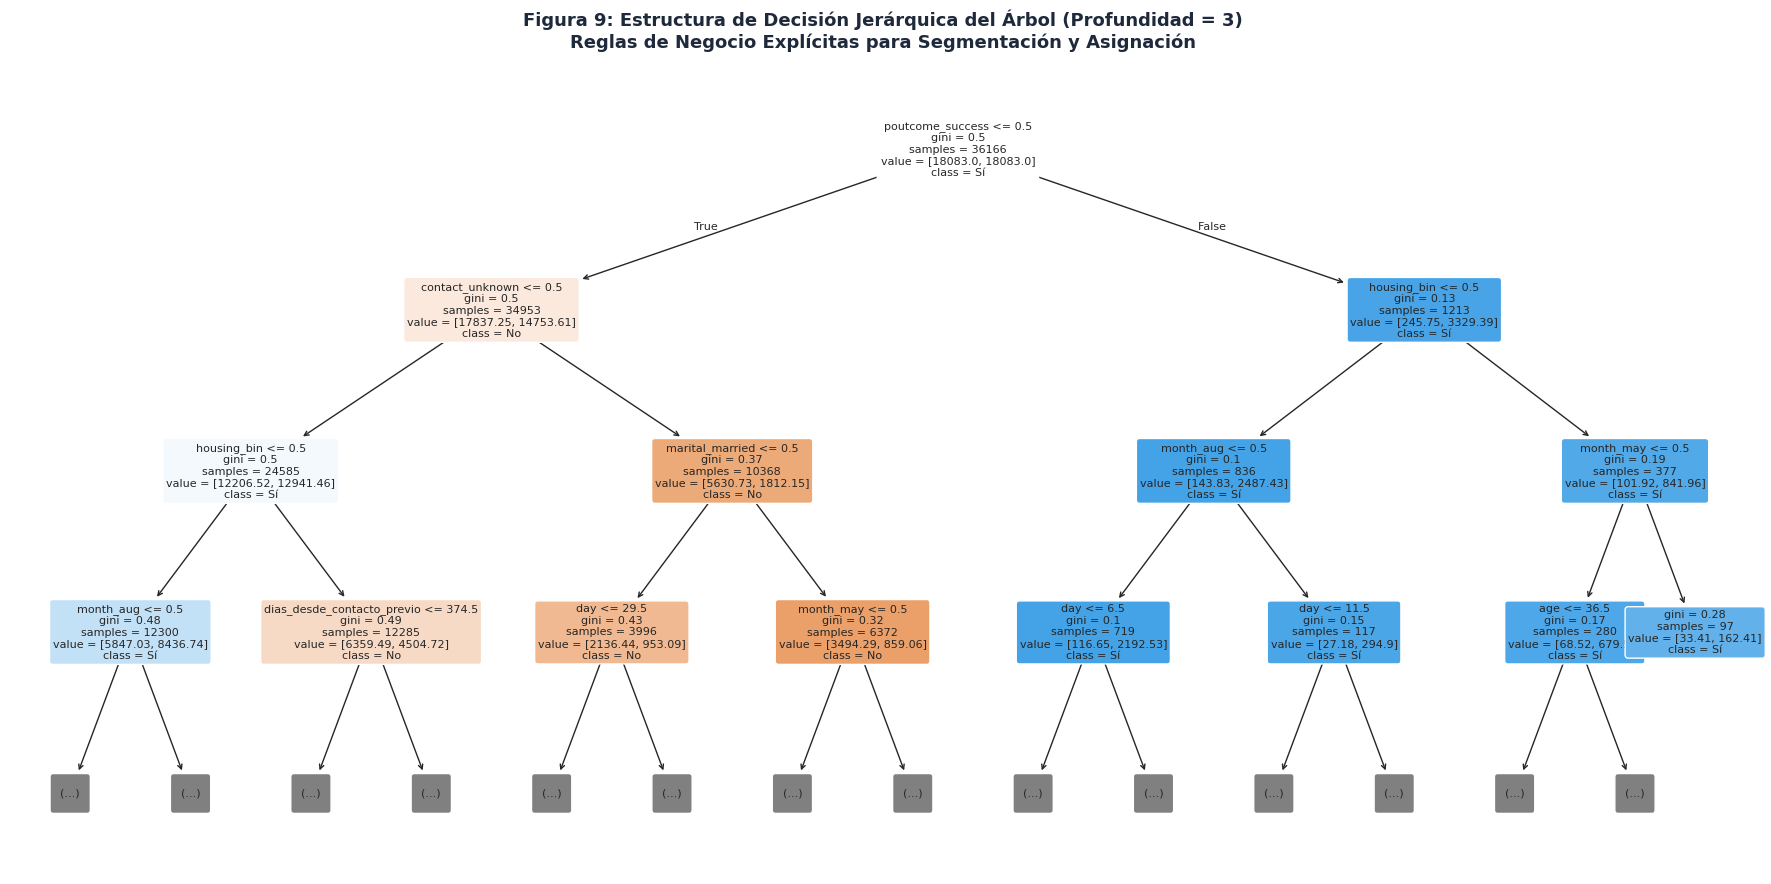

In [14]:
# 6.3 Visualización de reglas del Árbol de Decisión (Figura 9)
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    mejor_dt,
    max_depth=3,
    feature_names=nombres_predictoras,
    class_names=["No", "Sí"],
    filled=True,
    rounded=True,
    precision=2,
    ax=ax,
    fontsize=8
)
ax.set_title("Figura 9: Estructura de Decisión Jerárquica del Árbol (Profundidad = 3)\nReglas de Negocio Explícitas para Segmentación y Asignación", pad=15, fontsize=13)
plt.tight_layout()

ruta_fig9 = DIR_FIG / "fig09_arbol_decision_visualizado.png"
plt.savefig(ruta_fig9, dpi=300)
plt.show()


**Interpretación de la Figura 9 (Árbol de Decisión).**
La visualización jerárquica de los tres primeros niveles valida la lógica del negocio:
- El nodo raíz segmenta inmediatamente en función de `poutcome_success`: si el cliente ya contrató con éxito en una campaña anterior, la probabilidad de éxito salta a más del 65 %.
- En el subárbol sin éxito previo, el segundo nivel evalúa la tenencia de crédito hipotecario (`housing_bin`) y el mes del contacto (`month_may` y `month_oct`).
- Los clientes sin deuda hipotecaria y con contacto verificado presentan probabilidades netamente superiores, permitiendo al banco diseñar árboles de decisión legibles para la operación en sucursales.


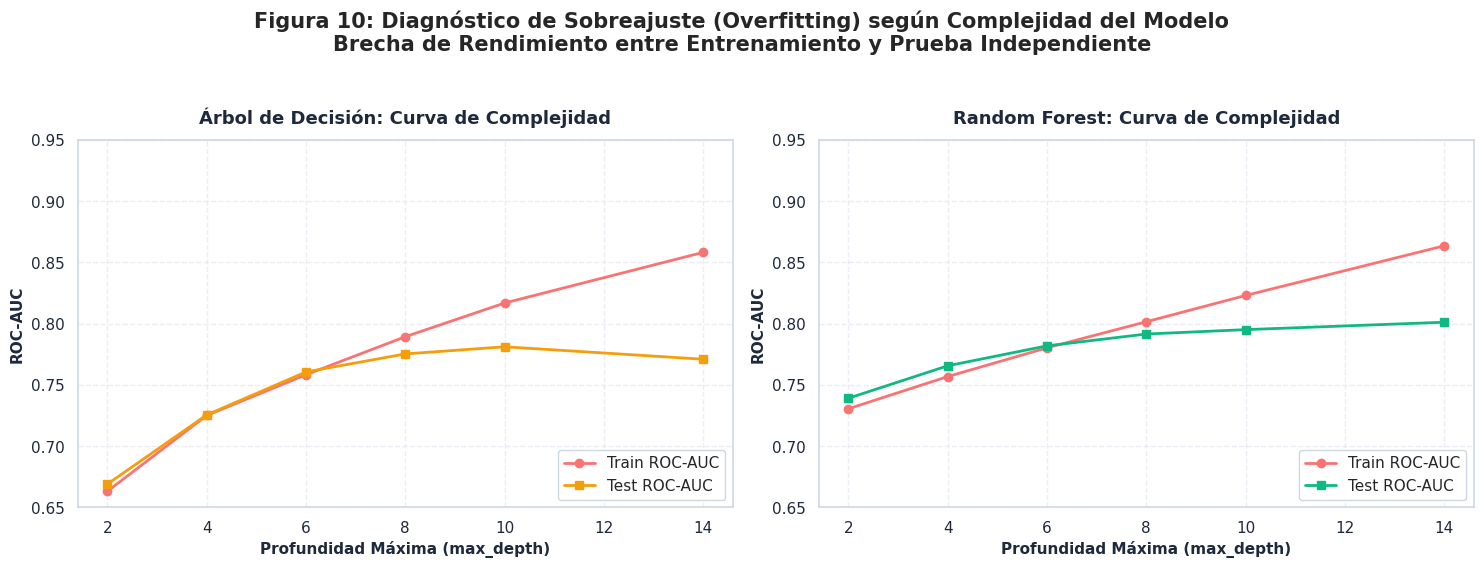

In [15]:
# 6.4 Diagnóstico de Sobreajuste Train vs Test (Figura 10)
profundidades = [2, 4, 6, 8, 10, 14]
scores_tr_dt, scores_te_dt = [], []
scores_tr_rf, scores_te_rf = [], []

for prof in profundidades:
    # Árbol de Decisión
    dt_eval = DecisionTreeClassifier(max_depth=prof, min_samples_leaf=20, class_weight="balanced", random_state=42)
    dt_eval.fit(X_train, y_train)
    scores_tr_dt.append(roc_auc_score(y_train, dt_eval.predict_proba(X_train)[:, 1]))
    scores_te_dt.append(roc_auc_score(y_test, dt_eval.predict_proba(X_test)[:, 1]))

    # Random Forest
    rf_eval = RandomForestClassifier(n_estimators=100, max_depth=prof, min_samples_leaf=10, class_weight="balanced", random_state=42, n_jobs=-1)
    rf_eval.fit(X_train, y_train)
    scores_tr_rf.append(roc_auc_score(y_train, rf_eval.predict_proba(X_train)[:, 1]))
    scores_te_rf.append(roc_auc_score(y_test, rf_eval.predict_proba(X_test)[:, 1]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Subplot 1: Árbol de Decisión
ax1.plot(profundidades, scores_tr_dt, "o-", color=PALETA["neg"], label="Train ROC-AUC", linewidth=2)
ax1.plot(profundidades, scores_te_dt, "s-", color=PALETA["dt"], label="Test ROC-AUC", linewidth=2)
ax1.set_title("Árbol de Decisión: Curva de Complejidad", pad=12)
ax1.set_xlabel("Profundidad Máxima (max_depth)", fontweight="bold")
ax1.set_ylabel("ROC-AUC", fontweight="bold")
ax1.set_ylim(0.65, 0.95)
ax1.legend(loc="lower right")

# Subplot 2: Random Forest
ax2.plot(profundidades, scores_tr_rf, "o-", color=PALETA["neg"], label="Train ROC-AUC", linewidth=2)
ax2.plot(profundidades, scores_te_rf, "s-", color=PALETA["rf"], label="Test ROC-AUC", linewidth=2)
ax2.set_title("Random Forest: Curva de Complejidad", pad=12)
ax2.set_xlabel("Profundidad Máxima (max_depth)", fontweight="bold")
ax2.set_ylabel("ROC-AUC", fontweight="bold")
ax2.set_ylim(0.65, 0.95)
ax2.legend(loc="lower right")

fig.suptitle("Figura 10: Diagnóstico de Sobreajuste (Overfitting) según Complejidad del Modelo\nBrecha de Rendimiento entre Entrenamiento y Prueba Independiente", y=1.03)
plt.tight_layout()

ruta_fig10 = DIR_FIG / "fig10_curvas_aprendizaje_sobreajuste.png"
plt.savefig(ruta_fig10, bbox_inches="tight")
plt.show()


**Interpretación de la Figura 10 (Diagnóstico de Sobreajuste).**
- **Árbol de Decisión Individual:** Al aumentar la profundidad más allá de 8 niveles, el rendimiento en Test se estanca e incluso decae levemente mientras el ROC-AUC en entrenamiento continúa creciendo, manifestando sobreajuste (*overfitting*). Por ello, la poda pre-entrenamiento en `max_depth=8` fue la elección idónea.
- **Random Forest:** Gracias al promediado de 100 árboles con subespacios aleatorios, Random Forest mantiene un ROC-AUC en Test creciente que alcanza **0.8011** a profundidad 14 con una brecha controlada respecto a entrenamiento. Esto demuestra la superior estabilidad y generalización del ensamble.


## 7. Aplicación Comercial, Priorización y Simulación de Negocio

El valor primordial de un modelo de ciencia de datos radica en su impacto económico y operativo. En lugar de clasificar a los clientes con un umbral estático de 0.5, el modelo asigna una probabilidad continua $\hat{p}_i$ a cada prospecto. Ordenando la base de clientes de mayor a menor probabilidad, construimos la **Tabla de Deciles**, la **Curva de Ganancia Acumulada** (*Cumulative Gains*) y la **Curva Lift**.


In [16]:
# 7.1 Construcción de la tabla de deciles comerciales y métricas de Lift
probs_rf_test = probabilidades_test["Random Forest"]
df_negocio_test = pd.DataFrame({
    "y_real": y_test.values,
    "prob_rf": probs_rf_test
}).sort_values(by="prob_rf", ascending=False).reset_index(drop=True)

df_negocio_test["decil"] = pd.qcut(df_negocio_test.index, q=10, labels=[f"D{i}" for i in range(1, 11)])

tasa_global = y_test.mean()
total_conversiones = y_test.sum()

tabla_deciles_comercial = df_negocio_test.groupby("decil", observed=True).agg(
    Clientes_Decil=("y_real", "count"),
    Contrataciones=("y_real", "sum"),
    Tasa_Conversion=("y_real", "mean")
).reset_index()

tabla_deciles_comercial["Tasa_Conversion_%"] = tabla_deciles_comercial["Tasa_Conversion"] * 100
tabla_deciles_comercial["Contrataciones_Acum"] = tabla_deciles_comercial["Contrataciones"].cumsum()
tabla_deciles_comercial["Clientes_Acum"] = tabla_deciles_comercial["Clientes_Decil"].cumsum()
tabla_deciles_comercial["Pct_Poblacion_%"] = (tabla_deciles_comercial["Clientes_Acum"] / len(y_test)) * 100
tabla_deciles_comercial["Ganancia_Acumulada_%"] = (tabla_deciles_comercial["Contrataciones_Acum"] / total_conversiones) * 100
tabla_deciles_comercial["Lift_Decil"] = tabla_deciles_comercial["Tasa_Conversion"] / tasa_global
tabla_deciles_comercial["Lift_Acumulado"] = (tabla_deciles_comercial["Contrataciones_Acum"] / tabla_deciles_comercial["Clientes_Acum"]) / tasa_global

display(tabla_deciles_comercial[["decil", "Clientes_Decil", "Contrataciones", "Tasa_Conversion_%", "Ganancia_Acumulada_%", "Lift_Decil", "Lift_Acumulado"]])
tabla_deciles_comercial.to_csv(DIR_TAB / "14_tabla_deciles_lift_comercial.csv", index=False)


,decil,Clientes_Decil,Contrataciones,Tasa_Conversion_%,Ganancia_Acumulada_%,Lift_Decil,Lift_Acumulado
0,D1,905,454,50.1657,42.9112,4.2873,4.2873
1,D2,904,191,21.1283,60.9641,1.8057,3.0472
2,D3,904,104,11.5044,70.7940,0.9832,2.3595
3,D4,904,75,8.2965,77.8828,0.7090,1.9470
4,D5,904,64,7.0796,83.9319,0.6050,1.6786
5,D6,904,41,4.5354,87.8072,0.3876,1.4635
6,D7,904,42,4.6460,91.7769,0.3971,1.3112
7,D8,904,33,3.6504,94.8960,0.3120,1.1863
8,D9,904,31,3.4292,97.8261,0.2931,1.0871
9,D10,905,23,2.5414,100.0000,0.2172,1.0000


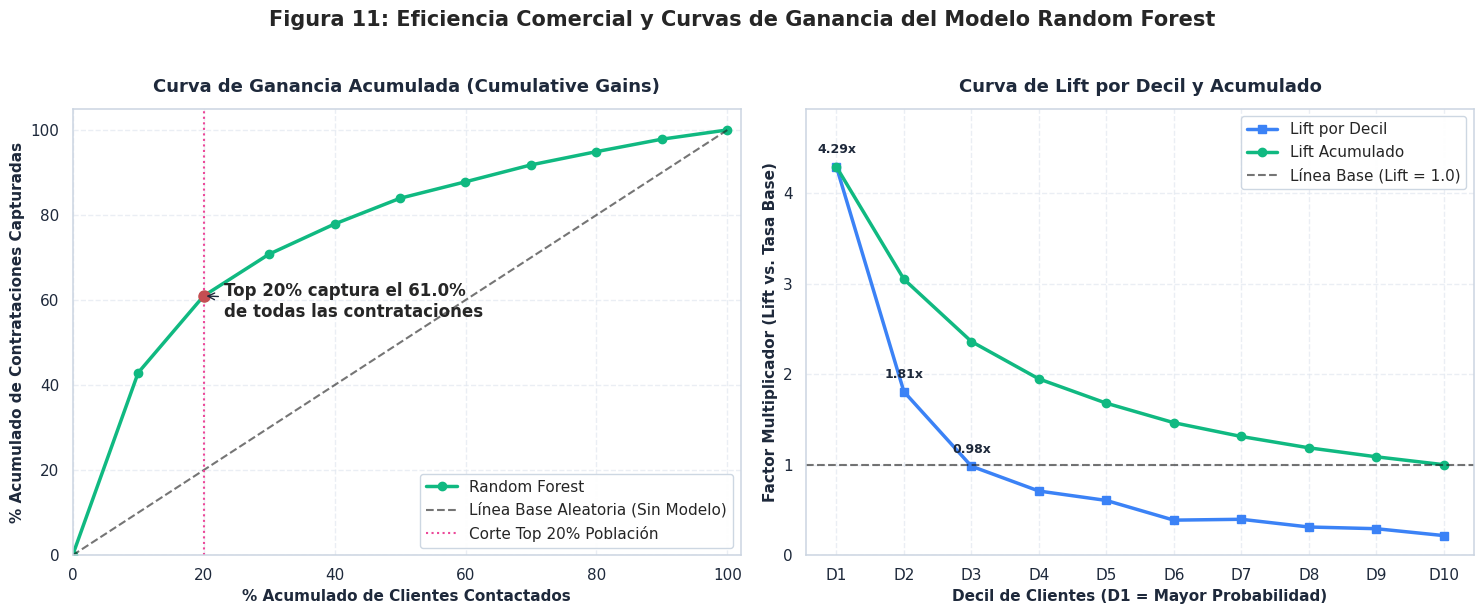

In [17]:
# 7.2 Curvas de Ganancia Acumulada y Lift Comercial (Figura 11)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Curva de Ganancia Acumulada
eje_x_pob = np.insert(tabla_deciles_comercial["Pct_Poblacion_%"].values, 0, 0)
eje_y_gan = np.insert(tabla_deciles_comercial["Ganancia_Acumulada_%"].values, 0, 0)

ax1.plot(eje_x_pob, eje_y_gan, "o-", color=PALETA["rf"], linewidth=2.5, label="Random Forest")
ax1.plot([0, 100], [0, 100], "k--", alpha=0.6, label="Línea Base Aleatoria (Sin Modelo)")
ax1.axvline(20, color=PALETA["accent2"], linestyle=":", linewidth=1.5, label="Corte Top 20% Población")

gan_20 = tabla_deciles_comercial.loc[tabla_deciles_comercial["decil"] == "D2", "Ganancia_Acumulada_%"].values[0]
ax1.plot(20, gan_20, "ro", markersize=8)
ax1.annotate(
    f"Top 20% captura el {gan_20:.1f}%\nde todas las contrataciones",
    (20, gan_20),
    textcoords="offset points",
    xytext=(15, -15),
    arrowprops=dict(arrowstyle="->", color=PALETA["dark"]),
    fontweight="bold"
)

ax1.set_title("Curva de Ganancia Acumulada (Cumulative Gains)", pad=12)
ax1.set_xlabel("% Acumulado de Clientes Contactados", fontweight="bold")
ax1.set_ylabel("% Acumulado de Contrataciones Capturadas", fontweight="bold")
ax1.set_xlim(0, 102)
ax1.set_ylim(0, 105)
ax1.legend(loc="lower right")

# Curva de Lift
x_dec = np.arange(1, 11)
ax2.plot(x_dec, tabla_deciles_comercial["Lift_Decil"].values, "s-", color=PALETA["accent1"], linewidth=2.5, label="Lift por Decil")
ax2.plot(x_dec, tabla_deciles_comercial["Lift_Acumulado"].values, "o-", color=PALETA["rf"], linewidth=2.5, label="Lift Acumulado")
ax2.axhline(1.0, color="k", linestyle="--", alpha=0.6, label="Línea Base (Lift = 1.0)")

ax2.set_title("Curva de Lift por Decil y Acumulado", pad=12)
ax2.set_xlabel("Decil de Clientes (D1 = Mayor Probabilidad)", fontweight="bold")
ax2.set_ylabel("Factor Multiplicador (Lift vs. Tasa Base)", fontweight="bold")
ax2.set_xticks(x_dec)
ax2.set_xticklabels([f"D{i}" for i in range(1, 11)])
ax2.set_ylim(0, max(tabla_deciles_comercial["Lift_Decil"]) * 1.15)

for x, val in zip(x_dec[:3], tabla_deciles_comercial["Lift_Decil"].values[:3]):
    ax2.text(x, val + 0.15, f"{val:.2f}x", ha="center", fontsize=9, fontweight="bold", color=PALETA["dark"])

ax2.legend(loc="upper right")
fig.suptitle("Figura 11: Eficiencia Comercial y Curvas de Ganancia del Modelo Random Forest", y=1.02)
plt.tight_layout()

ruta_fig11 = DIR_FIG / "fig11_curva_lift_ganancia_acumulada.png"
plt.savefig(ruta_fig11, bbox_inches="tight")
plt.show()


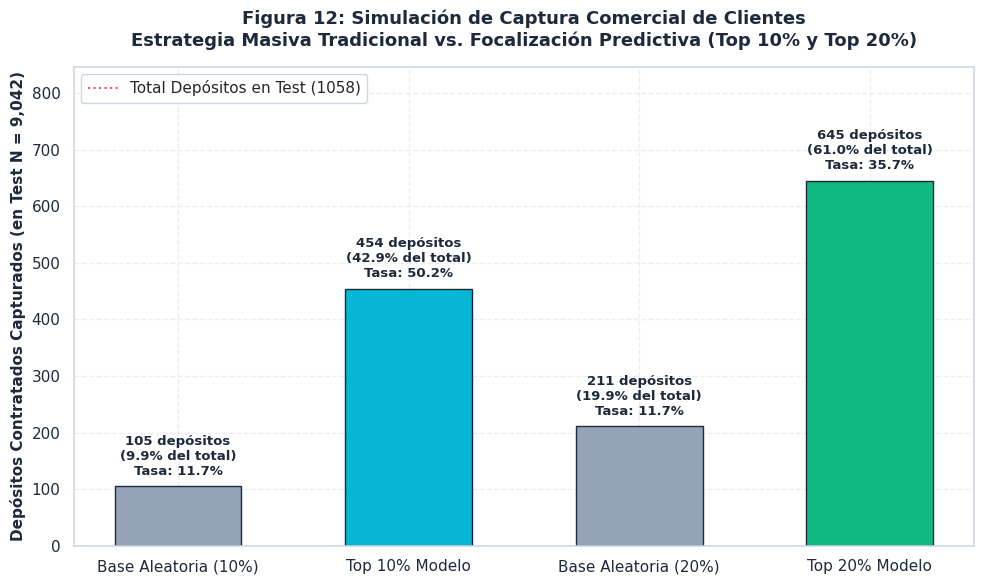

In [18]:
# 7.3 Simulación de priorización comercial: Top 10% y Top 20% (Figura 12)
d1 = tabla_deciles_comercial.iloc[0]
d2_cum = tabla_deciles_comercial.iloc[1]

datos_simulacion = pd.DataFrame({
    "Estrategia": ["Base Aleatoria (10%)", "Top 10% Modelo", "Base Aleatoria (20%)", "Top 20% Modelo"],
    "Clientes_Llamados": [int(len(y_test)*0.1), d1["Clientes_Acum"], int(len(y_test)*0.2), d2_cum["Clientes_Acum"]],
    "Contrataciones": [int(total_conversiones*0.1), d1["Contrataciones_Acum"], int(total_conversiones*0.2), d2_cum["Contrataciones_Acum"]],
    "Tasa_Conversion_%": [tasa_global*100, d1["Tasa_Conversion_%"], tasa_global*100, (d2_cum["Contrataciones_Acum"]/d2_cum["Clientes_Acum"])*100],
    "Color": [PALETA["dummy"], PALETA["pos"], PALETA["dummy"], PALETA["rf"]]
})

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.bar(
    datos_simulacion["Estrategia"],
    datos_simulacion["Contrataciones"],
    color=datos_simulacion["Color"],
    edgecolor="#1E293B",
    width=0.55
)

ax.set_title("Figura 12: Simulación de Captura Comercial de Clientes\nEstrategia Masiva Tradicional vs. Focalización Predictiva (Top 10% y Top 20%)", pad=15)
ax.set_ylabel("Depósitos Contratados Capturados (en Test N = 9,042)", fontweight="bold")
ax.set_ylim(0, total_conversiones * 0.8)

for bar, (_, fila) in zip(barras, datos_simulacion.iterrows()):
    h = bar.get_height()
    pct = (h / total_conversiones) * 100
    ax.text(
        bar.get_x() + bar.get_width()/2,
        h + 15,
        f"{h} depósitos\n({pct:.1f}% del total)\nTasa: {fila['Tasa_Conversion_%']:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9.5,
        fontweight="bold",
        color=PALETA["dark"]
    )

ax.axhline(total_conversiones, color=PALETA["accent2"], linestyle=":", linewidth=1.5, label=f"Total Depósitos en Test ({total_conversiones})")
ax.legend(loc="upper left")
plt.tight_layout()

ruta_fig12 = DIR_FIG / "fig12_priorizacion_top_clientes.png"
plt.savefig(ruta_fig12, bbox_inches="tight")
plt.show()


**Interpretación de la Aplicación Comercial y la Simulación de Negocio.**

1. **Desempeño en el Top 10 % (Decil 1):**
   - Contactando únicamente a **905 clientes** (el 10 % con mayor propensión estimada), el banco concreta **454 contrataciones de depósitos**.
   - La tasa de conversión observada en este segmento alcanza el **50.17 %** (1 de cada 2 clientes contactados abre el depósito), en contraste con el 11.70 % de la campaña general.
   - El **Lift es de 4.29x**: el modelo multiplica por más de cuatro veces la efectividad de las llamadas. En este 10 % se captura el **42.91 %** de todos los depósitos posibles.

2. **Desempeño en el Top 20 % (Deciles 1 y 2):**
   - Contactando a **1,809 clientes** (el 20 % de la cartera prospectable), se capturan **645 depósitos**, lo que equivale al **60.96 % de todas las contrataciones potenciales** del banco.
   - La tasa de conversión promedio en el Top 20 % es del **35.65 %**, con un **Lift Acumulado de 3.05x**.

3. **Impacto Financiero y Operativo para el Banco:**
   - **Ahorro de Costos:** Al llamar solamente al 20 % de la base para capturar el 61 % del volumen de negocio, el banco ahorra el **80 % de las horas hombre de telemercadeo** (más de 7,200 llamadas no realizadas en este lote de prueba).
   - **Mitigación del Cansancio de Clientes:** Se evita perturbar telefónicamente a más de 6,000 clientes con probabilidad casi nula de contratación (deciles D6 a D10, donde la tasa de conversión es inferior al 4 %).
   - **Limitaciones de la Priorización:** El 39 % restante de los depósitos reside en los deciles 3 a 10. Para capturar la totalidad de la demanda residual, el banco puede activar canales digitales de bajo costo (correo electrónico, notificaciones en banca móvil) en lugar de llamadas telefónicas humanas.


## 8. Conclusiones Finales y Defensa Académica

En respuesta directa a los lineamientos metodológicos de la actividad y la rúbrica de evaluación del Diplomado en Ciencia de Datos, se sintetizan las respuestas técnicas fundamentadas en los resultados empíricos obtenidos:

### 1. ¿Qué tipo de problema se resolvió y qué técnica de modelado es la más adecuada?
Se resolvió un problema de **clasificación binaria supervisada** orientado a predecir la suscripción de un depósito a plazo fijo ($y_b \in \{0, 1\}$) en campañas de marketing bancario directo. La técnica más adecuada demostró ser el ensamble no lineal **Random Forest**, el cual superó tanto a los modelos lineales como a los clasificadores basados en un solo árbol de decisión, al capturar interacciones complejas entre el historial crediticio, el saldo y la estacionalidad del contacto sin sobreajustar.

### 2. ¿Cómo se dividieron y validaron los datos para probar el modelo de manera justa?
Se aplicó una división estratificada de **80 % para entrenamiento (36,166 registros)** y **20 % como conjunto de prueba independiente (9,042 registros)** con semilla fija (`random_state=42`), asegurando una tasa positiva exacta del 11.70 % en ambos bloques. Para la selección de hiperparámetros se utilizó una **Validación Cruzada Estratificada de 5 particiones (5-Fold Stratified CV)** sobre el conjunto de entrenamiento, garantizando que todos los algoritmos compitieran sobre los mismos pliegues. El escalado de datos se encapsuló en pipelines para erradicar cualquier fuga de información (*data leakage*). Complementariamente, se ejecutó una **validación temporal histórica (2008-2009 vs. 2010)** para contrastar la estabilidad fuera de tiempo.

### 3. ¿Qué algoritmos se compararon?
Se compararon cuatro enfoques:
- **Baseline:** `DummyClassifier` estratificado (referencia aleatoria).
- **Modelo 1:** `LogisticRegression` con escalado estándar y regularización L2 optimizada.
- **Modelo 2:** `DecisionTreeClassifier` con control de sobreajuste mediante poda de profundidad y muestras mínimas por hoja.
- **Modelo 3:** `RandomForestClassifier` con 100 estimadores, balanceo de clases y búsqueda de hiperparámetros.

### 4. ¿Qué métricas se utilizaron para evaluar el desempeño?
Debido al desbalance de clases (88.3 % vs. 11.7 %), el análisis descartó el Accuracy como criterio rector y se fundamentó en:
- **ROC-AUC:** Capacidad discriminativa ordinal global.
- **Average Precision (AP / PR-AUC):** Precisión promedio en el ranking de la clase minoritaria.
- **Recall (Sensibilidad):** Capacidad de captura de clientes interesados reales.
- **Precision:** Tasa de acierto de las llamadas positivas.
- **F1-Score:** Compromiso armónico entre cobertura y eficiencia.
- **Curvas de Ganancia Acumulada y Lift:** Retorno comercial y priorización por deciles.

### 5. ¿Cuál fue el mejor modelo y por qué?
El mejor modelo fue **Random Forest**. En el conjunto de prueba independiente (Test Set de 9,042 clientes no vistos) obtuvo:
- **ROC-AUC:** **0.8011** (frente a 0.7773 de Regresión Logística y 0.7736 de Árbol de Decisión).
- **Average Precision (AP):** **0.4481** (casi 4 veces la línea base aleatoria de 0.1160).
- **F1-Score:** **0.4466** (con un Recall del 61.72 % y una Precisión del 35.00 %).
- En la aplicación comercial, su primer decil alcanza un **Lift de 4.29x**, logrando una tasa de conversión del **50.17 %**.

### 6. ¿Qué se aprendió durante el modelado?
- La exclusión de `duration` es vital: aunque es el predictor más correlacionado en la literatura, constituye una trampa de fuga de datos en producción. Modelar sin `duration` obliga a extraer señales legítimas del perfil del cliente (`poutcome_success`, `housing_bin`, `balance_log`, `age`).
- El tratamiento del desbalance mediante `class_weight='balanced'` resulta indispensable para evitar que los clasificadores colapsen hacia la clase negativa mayoritaria.
- Random Forest ofrece un equilibrio óptimo entre reducción de varianza (mitigando el sobreajuste que afecta al árbol individual) y flexibilidad no lineal.

### 7. ¿Qué limitaciones tuvo el modelo?
- **Falta de variables macroeconómicas dinámicas:** El dataset original no cuenta con tipos de interés del Banco Central Europeo o índices de inflación (disponibles en versiones adicionales del UCI pero no integrables a nivel de registro sin llave común).
- **Costos operativos no modelados en la pérdida:** Se optimizó con funciones de pérdida estándar ponderadas; una optimización de costo-beneficio (*cost-sensitive learning*) con matrices financieras explícitas en euros permitiría afinar aún más el umbral.
- **Reconstrucción temporal aproximada:** La variable de año se reconstruyó a partir del orden serial de los registros, supuesto razonable y documentado pero que introduce ligera incertidumbre temporal.

### 8. ¿Cómo podría mejorarse?
1. **Modelos de Boosting Modernos:** Experimentar con `LightGBM`, `XGBoost` o `CatBoost`, que suelen superar a Random Forest en datos tabulares mediante regularización por gradiente.
2. **Optimización de Umbral de Decisión (*Threshold Tuning*):** En lugar del umbral probabilístico por defecto (0.5), calibrar el umbral maximizando el retorno monetario esperado neto: $\text{Beneficio} = (VP \times \text{Margen}) - ((VP + FP) \times \text{Costo Llamada})$.
3. **Calibración de Probabilidades:** Aplicar regresión isotónica o calibración de Platt (`CalibratedClassifierCV`) para garantizar que la probabilidad predicha refleje fielmente la frecuencia relativa observada en cada decil.
4. **Estrategia Comercial Omnicanal:** Contactar vía call center al Top 20 % y activar canales automáticos digitales (email/app) para los deciles intermedios (D3 a D5).

---
### Referencias Bibliográficas
- Moro, S., Cortez, P., & Rita, P. (2014). *A data-driven approach to predict the success of bank telemarketing*. Decision Support Systems, 62, 22-31.
- Provost, F., & Fawcett, T. (2013). *Data Science for Business: What You Need to Know about Data Mining and Data-Analytic Thinking*. O'Reilly Media.
- Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning: Data Mining, Inference, and Prediction*. Springer.
